# Phase 3 · NB09 · TREAD-TWO / ATLAS completed-run review

**CPU only · no training or new inference · direct CSV + interactive evidence · additive HF publication.**

NB08 completed all 60 epochs / 2,940 updates. Both selected/final balanced
accuracies are 50%. The actual confusion is **62 low → mid, 41 high → high**.
This notebook audits the saved run and publishes new post-hoc tables, figures,
source/provenance and a complete interactive failure/probe explorer.

## Kaggle settings

1. Accelerator **None / CPU**, Internet **ON**. No T4 allocation is needed.
2. **No dataset attachment needed**: all inputs and source images come from
   the pinned completed NB08 evidence; no new model forward pass occurs.
3. Keep at least **2 GiB free**. Selected scientific input is about 150 MB;
   local evidence, derived output and publication staging stay well below 20 GB.
4. Enable **HF_TOKEN** in Kaggle Secrets with write access to
   **Shanmuk4622/tyre-wear-study**. It is read only by the final publication cell.
5. **Run All**. The tested Hub transport dependency is pinned; Torch/CUDA and
   other model packages are not changed.

Inputs are pinned to revision `82e7e1c5774f54c786571cdef7b3b60c1e96630f`.
Every consumed file is verified by size and SHA-256. Interrupted/partial
downloads are fetched again; verified completed objects are reused. Derived
tables are atomic deterministic recomputations, not another training trajectory.
No original fit/checkpoint/CSV namespace or workstation is overwritten.


In [1]:
import base64,hashlib,importlib.metadata,json,os,signal,subprocess,sys,shutil,time
from pathlib import Path
from filelock import FileLock
assert Path('/kaggle/working').exists(),'Run NB09 on Kaggle CPU.'
WORK=Path('/kaggle/working/tread_two_nb09_review')
WORK.mkdir(parents=True,exist_ok=True)
assert shutil.disk_usage(WORK).free>=2*1024**3,'Keep at least 2 GiB free for evidence, output and immutable publication staging.'
os.environ['HF_HUB_DISABLE_IMPLICIT_TOKEN']='1'
try: hub=importlib.metadata.version('huggingface_hub')
except importlib.metadata.PackageNotFoundError: hub=None
if hub!='0.36.2': subprocess.check_call([sys.executable,'-m','pip','install','--disable-pip-version-check','huggingface_hub==0.36.2'])
payload=json.loads(base64.b64decode('...'))
with FileLock(str(WORK/'SESSION.lock'),timeout=1):
    for name,value in payload.items():
        target=(WORK/name).resolve()
        assert target.is_relative_to(WORK.resolve()) and '..' not in Path(name).parts
        body=base64.b64decode(value)
        if target.exists(): assert target.read_bytes()==body,'Preserve this review; its existing source differs.'
        else:
            target.parent.mkdir(parents=True,exist_ok=True)
            target.write_bytes(body)
OUT=WORK/'analysis_report'
CACHE=WORK/'cache'
common=['--out',str(OUT),'--source',str(WORK/'frozen_source'),'--launcher',str(WORK/'transport/nb08_transport_launcher.py'),'--manifest',str(WORK/'FIT_MANIFEST.json'),'--work',str(WORK/'publication')]
def launch(script,args,token=None):
    environment=dict(os.environ)
    environment.pop('HF_TOKEN',None)
    if token is not None: environment['HF_TOKEN']=token
    with FileLock(str(WORK/'SESSION.lock'),timeout=1):
        child=subprocess.Popen([sys.executable,'-B','-u',str(WORK/'review'/script),*args],env=environment,start_new_session=True)
        environment.pop('HF_TOKEN',None)
        try:
            while True:
                try: status=child.wait(timeout=15);break
                except subprocess.TimeoutExpired: pass
        except KeyboardInterrupt:
            if child.poll() is None:
                os.killpg(child.pid,signal.SIGINT)
                for i in range(120):
                    try: child.wait(timeout=5);break
                    except subprocess.TimeoutExpired:
                        if i%6==0: print('Waiting for safe read cleanup or completed-review HF flush; preserve local files.',flush=True)
            raise
        assert status==0,'Review stage stopped; keep working files and rerun. Completed verified reads are reused.'
print('Review source ready. CPU only; no dataset attachment or training launch. No secret read yet.')


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 6.3 MB/s  0:00:00
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface_hub 1.29.0
    Uninstalling huggingface_hub-1.29.0:
      Successfully uninstalled huggingface_hub-1.29.0


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
transformers 5.16.1 requires huggingface-hub<2.0,>=1.5.0, but you have huggingface-hub 0.36.2 which is incompatible.


Review source ready. CPU only; no dataset attachment or training launch. No secret read yet.


## 1 · Analyse retained evidence and prepare publication

Checks cover all 29,410 predictions, 23,520 training exposures, 2,940 updates,
60 selections, 824 probe pairs, all 1,030 endpoint/probe logit decompositions,
18 literal references, all 32 patch contributions and retained dense summaries.
The full 35.5-million-row source is not all downloaded/recounted; the exact
consumed subset and exclusions are recorded. All derived metrics remain
existing-cohort development evidence with no held-out mid targets.


In [2]:
launch('review_atlas.py',['--cache',str(CACHE),'--manifest',str(WORK/'FIT_MANIFEST.json'),'--out',str(OUT)])
launch('publish_atlas_review.py',common+['--prepare-only'])

Verified review input files: 50
Verified review input files: 100
Verified review input files: 150
Verified review input files: 200
Verified review input files: 250
Verified review input files: 300
Verified review input files: 350
Verified review input files: 400
Verified review input files: 450
Verified review input files: 500
{
  "status": "passed",
  "source_revision": "82e7e1c5774f54c786571cdef7b3b60c1e96630f",
  "source_protocol": "fe7dc763fe6d4b64ce8ccf2f22c4222b6da28ca7975c925d56ba70c3e09d19dd",
  "source_manifest_sha256": "d85029bf08faedb7f5dbe89927cc9a4718b96e719a89169f13ebd72220e9a54e",
  "source_prediction_rows": 29410,
  "completed_optimizer_updates": 2940,
  "selected_epoch": 18,
  "final_epoch": 60,
  "model_forward_calls": 0,
  "training_updates_performed": 0,
  "new_independent_tyres": 0,
  "remote_writes": 0,
  "all_large_source_families_recounted": false,
  "input_files": 522,
  "input_bytes": 147182968,
  "checks": [
    "All 29410 prediction IDs, roles, probabilities

## 2 · Inspect direct tables, figures and interactive records

Original and intervention scores are paired by image and checkpoint. Green/red
patch evidence and literal reference contributions are saved-score decompositions,
not causal wear measurements. Grayscale modifies query and bank; brightness
modifies query only. The atlas thumbnail remains the base atlas, explicitly labeled.


,stage,endpoint,variant,epoch,n,accuracy,balanced_accuracy_observed,nll,brier,ece_10_equal_width,mean_confidence,low_to_mid,predicted_low,predicted_mid,predicted_high
0,diagnostics,final,brightness_080,60,103,0.000000,0.0,1.669288,1.077964,0.635504,0.635504,62,0,103,0
1,diagnostics,final,brightness_120,60,103,0.398058,0.5,1.339821,0.818184,0.283068,0.665372,62,0,62,41
2,diagnostics,final,grayscale_both,60,103,0.000000,0.0,1.851557,1.164825,0.656914,0.656914,62,0,103,0
3,diagnostics,final,occlude_top_patch,60,103,0.398058,0.5,1.410791,0.864243,0.591105,0.612819,62,0,62,41
4,diagnostics,selected,brightness_080,18,103,0.398058,0.5,1.314844,0.821324,0.581364,0.529012,62,0,62,41
5,diagnostics,selected,brightness_120,18,103,0.398058,0.5,1.112140,0.660708,0.362107,0.548283,62,0,62,41
6,diagnostics,selected,grayscale_both,18,103,0.000000,0.0,1.496713,0.949007,0.549358,0.549358,62,0,103,0
7,diagnostics,selected,occlude_top_patch,18,103,0.398058,0.5,1.170823,0.702528,0.152680,0.550739,62,0,62,41
8,final_eval,final,identity,60,103,0.398058,0.5,1.428298,0.881229,0.602820,0.624546,62,0,62,41
9,selected_eval,selected,identity,18,103,0.398058,0.5,1.178296,0.711430,0.162204,0.560262,62,0,62,41


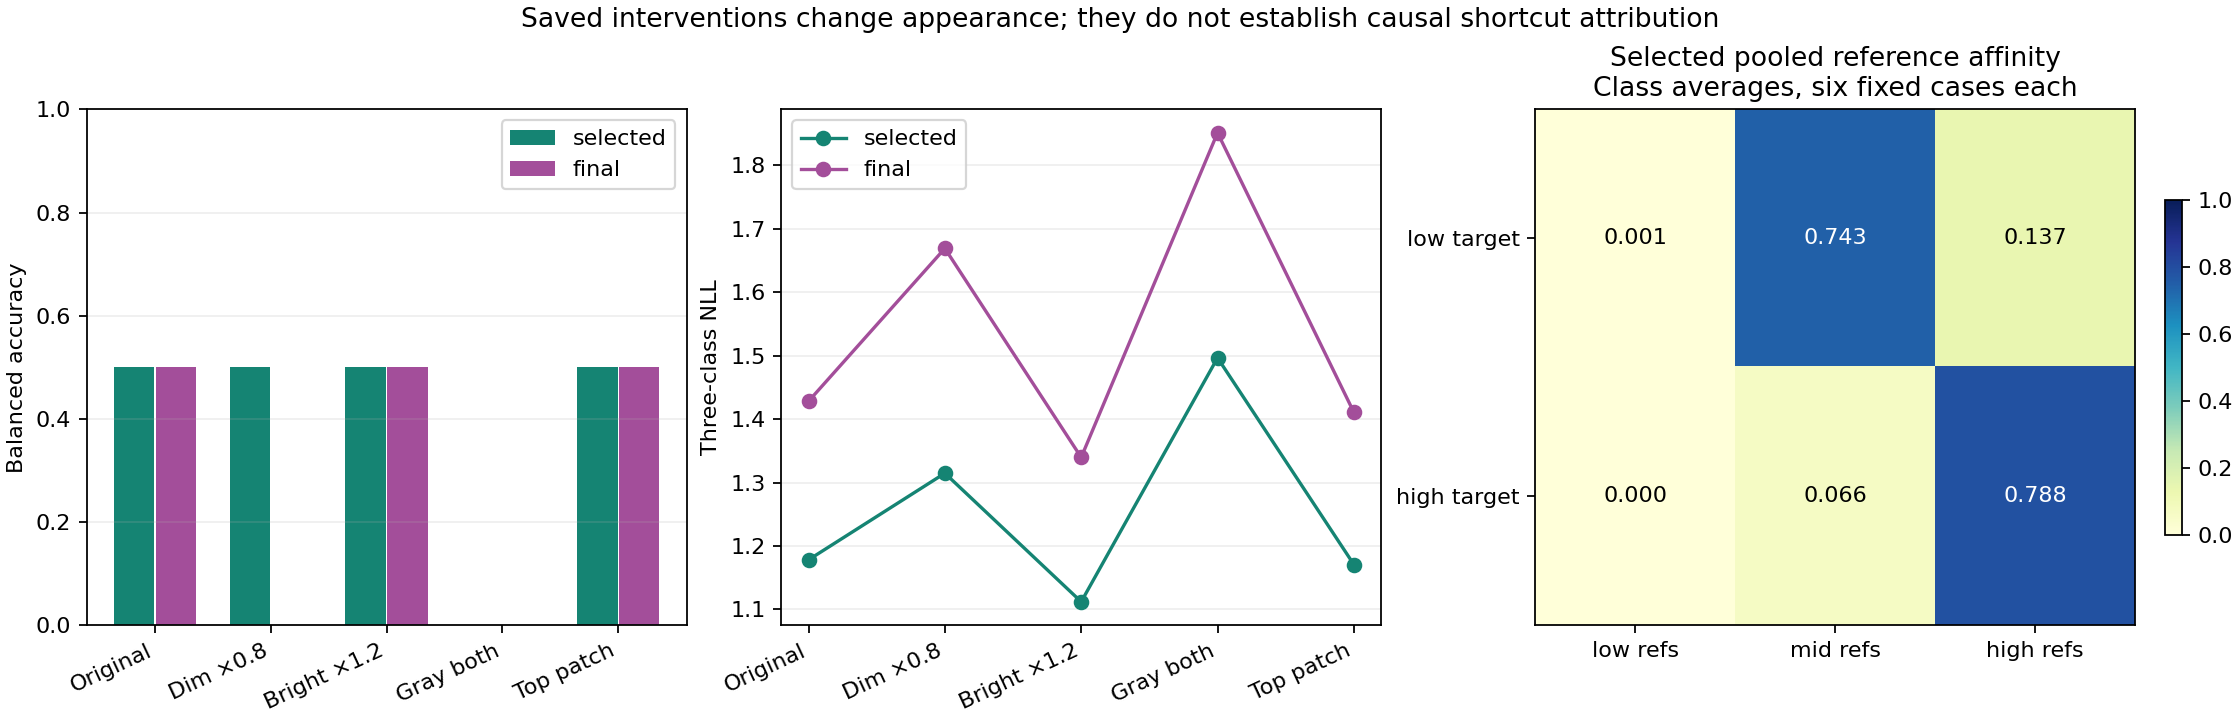

/kaggle/working/tread_two_nb09_review/analysis_report/ATLAS_Failure_Explorer.html

{
  "status": "prepared_not_published",
  "contract": "49e2f589866852cc7ad2d92d393b572de5d625d906f274ccf406830baf6186dd",
  "path": "/kaggle/working/tread_two_nb09_review/publication/bundle/49e2f5898668",
  "destination": "phase3/tread-two/atlas-v1/review/49e2f589866852cc7ad2d92d393b572de5d625d906f274ccf406830baf6186dd",
  "files": 51,
  "csv_tables": 30,
  "source_fit_unchanged": true,
  "model_training": false
}



In [3]:
from IPython.display import display,FileLink,Image
import pandas as pd
display(pd.read_csv(OUT/'cohort_metrics.csv').query("stage in ['selected_eval','final_eval','diagnostics']"))
display(Image(filename=str(OUT/'figures/probes_and_affinities.png')))
display(FileLink(str(OUT/'ATLAS_Failure_Explorer.html')))
print((WORK/'publication/REVIEW_DELIVERY.json').read_text())

## 3 · Publish the complete review directly to HF

The destination is a new `phase3/tread-two/atlas-v1/review/<contract>` namespace.
Original NB08 training remains untouched. CSVs, JSON, Python source, PNG and HTML
are uploaded directly, never as ZIP/NPZ/database bundles. The immutable publisher
checks remote Git/LFS metadata before selecting its final manifest and releases
ownership. An identical completed manifest is reused on rerun.

This finite analysis has one major completion flush, rather than periodic
training updates. Catchable Stop/error during publication attempts to finish or
retry the same complete local review, respecting server backoff. Forced kernel
death cannot publish unsent work; rerun the final cell with retained files.
An existing live writer is never stolen; allow its release/expiry.


In [4]:
from kaggle_secrets import UserSecretsClient
token=UserSecretsClient().get_secret('HF_TOKEN')
try:
    launch('publish_atlas_review.py',common,token=token)
finally:
    token=None
print((WORK/'publication/REVIEW_PUBLICATION.json').read_text())
print('Preserve this executed notebook for the independent HF completion audit. No model was trained or installed.')

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            
New Data Upload               : |          |  0.00B /  0.00B            

  ...probes_and_affinities.png:   2%|▏         | 2.76kB /  151kB            


  ...8668/prediction_audit.csv:   2%|▏         |  306kB / 16.7MB            



  ...LAS_Failure_Explorer.html:   2%|▏         |  380kB / 20.7MB            




  ...embedding_calibration.png:   2%|▏         | 2.16kB /  118kB            





  ...res/fit_and_confusion.png:   2%|▏         | 2.64kB /  144kB            






  ...ference_contributions.csv:   2%|▏         |  201kB / 11.0MB            







  ...dpoint_patch_evidence.csv:   2%|▏         |  223kB / 12.2MB            

  ...probes_and_affinities.png:   2%|▏         | 2.76kB /  151kB            


  ...8668/prediction_audit.csv:   2%|▏         |  306kB / 16.7MB            



  ...LAS_Failure_Explorer.html:   2%|▏         |  380kB / 20.7MB            




  ...embedding_calibration.png:   2%|▏        

{
  "status": "published_and_verified",
  "revision": "93d7ea34c5539769d122330141f96b1a23083b7a",
  "destination": "phase3/tread-two/atlas-v1/review/49e2f589866852cc7ad2d92d393b572de5d625d906f274ccf406830baf6186dd",
  "files": 51,
  "uploaded_objects": 50,
  "zip_uploads": 0,
  "owner_released": true
}
{
  "status": "published_and_verified",
  "revision": "93d7ea34c5539769d122330141f96b1a23083b7a",
  "destination": "phase3/tread-two/atlas-v1/review/49e2f589866852cc7ad2d92d393b572de5d625d906f274ccf406830baf6186dd",
  "files": 51,
  "uploaded_objects": 50,
  "zip_uploads": 0,
  "owner_released": true
}

Preserve this executed notebook for the independent HF completion audit. No model was trained or installed.
